# Mass and fragment ions

Calculate a neutral monoisotopic mass and locate the b and y fragment series.

A neutral peptide includes one water molecule in addition to the residue masses. A singly charged b ion includes one proton. A y ion carries a proton and retains the C-terminal water. The two series can account for the same backbone break.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import WATER, PROTON, RESIDUES, fragments
from pyteomics import mass

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

neutral mass 799.35996 Da
 b ions [ 98.06  227.103 324.155 425.203 538.287 653.314]
 y ions [148.06  263.087 376.171 477.219 574.272 703.314]


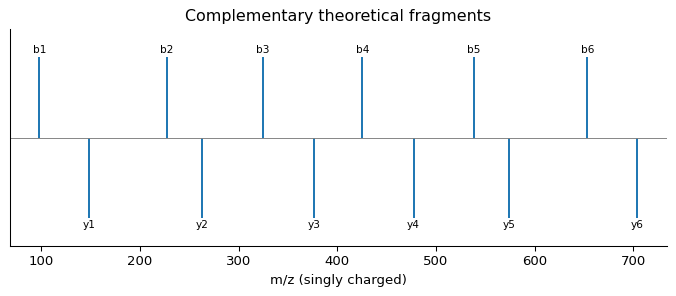

In [2]:
seq = "PEPTIDE"
neutral = WATER + sum(RESIDUES[x] for x in seq)
b, y = fragments(seq)
assert abs(neutral - mass.calculate_mass(sequence=seq)) < 1e-5
assert np.allclose(b + y[::-1], neutral + 2 * PROTON)
print(f"neutral mass {neutral:.5f} Da")
print(" b ions", np.round(b, 3))
print(" y ions", np.round(y, 3))
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
for label, z, sign in [("b", b, 1), ("y", y, -1)]:
    ax.vlines(z, 0, sign, label=label)
    for i, mz in enumerate(z):
        ax.text(
            mz,
            sign * 1.03,
            f"{label}{i+1}",
            fontsize=8,
            ha="center",
            va="bottom" if sign > 0 else "top",
        )
ax.set(
    xlabel="m/z (singly charged)",
    ylim=(-1.35, 1.35),
    yticks=[],
    title="Complementary theoretical fragments",
)
ax.axhline(0, color="0.5", lw=0.7)
plt.show()

## Interpreting the result

The sticks mark calculated positions. Their heights distinguish series rather than estimate an instrument response.

## Exercise

Replace one residue and identify which b and y ions change.

## References

[Pyteomics, peptide mass and charge calculations](https://pyteomics.readthedocs.io/en/latest/mass.html)